In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/1e275a2206db45a08b19f2545e2ae8f5:46562652-ebad-4e2b-a27a-1531217eb801::"
)

In [2]:
import pandas as pd
import numpy as np

TARGET = "01100"

JOBS = {
    "None": "dbm9mld8ft8s738uf8i0",
    "XpXm": "dbm9lvu74qds73drssp0",
    "XX": "dbm9val8mdtc73d7iuvg",
    "XY4": "dbma03u74qds73drticg",
    "Twirling": "dbm9mud8mdtc73d7iclg",
    "XpXm + Twirling": "dbm9kpu74qds73drsr20",
    "XX + Twirling": "dbm9uju74qds73drteug",
    "XY4 + Twirling": "dbma14m74qds73drtkng",
}

summary = []
distributions = []

for experiment, job_id in JOBS.items():

    print(f"Processing {experiment}...")

    job = service.job(job_id)

    if str(job.status()) not in ["DONE", "JobStatus.DONE"]:
        print("Skipping:", job.status())
        continue

    result = job.result()

    for pub_index, pub in enumerate(result):

        counts = pub.data.meas.get_counts()
        shots = sum(counts.values())

        target_counts = counts.get(TARGET, 0)
        probability = target_counts / shots

        stderr = np.sqrt(
            probability * (1 - probability) / shots
        )

        summary.append({
            "Experiment": experiment,
            "Job ID": job_id,
            "PUB": pub_index,
            "Shots": shots,
            "Target Counts": target_counts,
            "Success (%)": probability * 100,
            "Standard Error (%)": stderr * 100,
        })

        for i in range(32):
            state = format(i, "05b")

            distributions.append({
                "Experiment": experiment,
                "State": state,
                "Counts": counts.get(state, 0),
                "Probability (%)":
                    counts.get(state, 0) / shots * 100
            })

summary_df = pd.DataFrame(summary)
distribution_df = pd.DataFrame(distributions)

print(summary_df)

Processing None...
Processing XpXm...
Processing XX...
Processing XY4...
Processing Twirling...
Processing XpXm + Twirling...
Processing XX + Twirling...
Processing XY4 + Twirling...
        Experiment                Job ID  PUB  Shots  Target Counts  \
0             None  dbm9mld8ft8s738uf8i0    0   4096            617   
1             XpXm  dbm9lvu74qds73drssp0    0   4096            633   
2               XX  dbm9val8mdtc73d7iuvg    0   4096            140   
3              XY4  dbma03u74qds73drticg    0   4096            137   
4         Twirling  dbm9mud8mdtc73d7iclg    0   4096            480   
5  XpXm + Twirling  dbm9kpu74qds73drsr20    0   4096            312   
6    XX + Twirling  dbm9uju74qds73drteug    0   4096            103   
7   XY4 + Twirling  dbma14m74qds73drtkng    0   4096            122   

   Success (%)  Standard Error (%)  
0    15.063477            0.558895  
1    15.454102            0.564792  
2     3.417969            0.283891  
3     3.344727            0.2

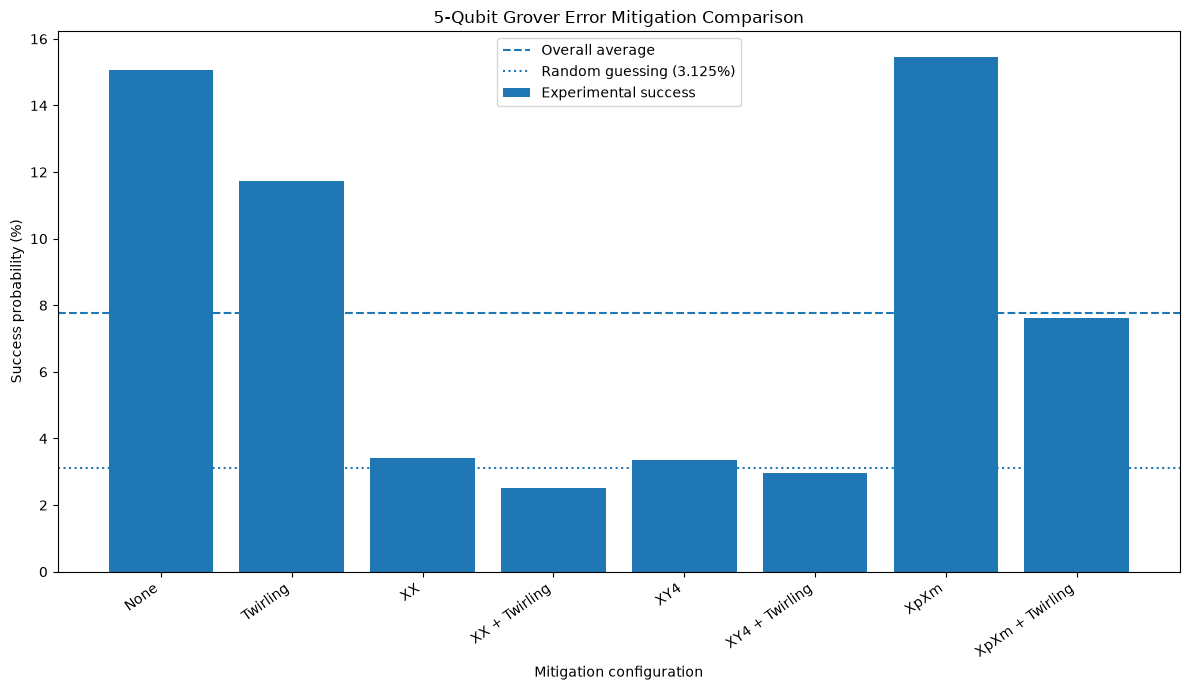


===== EXPORT COMPLETE =====
CSV: c:\Users\compu\Documents\Non-auto-gen\programming\Quantum_Computing\QC_RP_3\grover_comparison_analysis.csv True
PNG: c:\Users\compu\Documents\Non-auto-gen\programming\Quantum_Computing\QC_RP_3\grover_comparison.png True

===== RESULTS =====
     Experiment  Shots  Target Counts  Success (%)  Other Configurations Average (%)  Difference (%)
           None 4096.0          617.0    15.063477                          6.720843        8.342634
       Twirling 4096.0          480.0    11.718750                          7.198661        4.520089
             XX 4096.0          140.0     3.417969                          8.384487       -4.966518
  XX + Twirling 4096.0          103.0     2.514648                          8.513532       -5.998884
            XY4 4096.0          137.0     3.344727                          8.394950       -5.050223
 XY4 + Twirling 4096.0          122.0     2.978516                          8.447266       -5.468750
           XpXm 40

In [3]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check input
if "summary_df" not in globals() or summary_df.empty:
    raise ValueError("summary_df is missing or empty. Run the extraction cell first.")

# Aggregate jobs by configuration
analysis_df = summary_df.groupby("Experiment").apply(
    lambda g: pd.Series({
        "Shots": g["Shots"].sum(),
        "Target Counts": g["Target Counts"].sum(),
        "Success (%)": (
            g["Target Counts"].sum() / g["Shots"].sum()
        ) * 100
    }),
    include_groups=False
).reset_index()

# Leave-one-out average
analysis_df["Other Configurations Average (%)"] = [
    analysis_df.loc[
        analysis_df.index != i, "Success (%)"
    ].mean()
    for i in analysis_df.index
]

analysis_df["Difference (%)"] = (
    analysis_df["Success (%)"] -
    analysis_df["Other Configurations Average (%)"]
)

# Export CSV
csv_path = os.path.abspath("grover_comparison_analysis.csv")
analysis_df.to_csv(csv_path, index=False)

# Plot
plt.figure(figsize=(12, 7))

plt.bar(
    analysis_df["Experiment"],
    analysis_df["Success (%)"],
    label="Experimental success"
)

plt.axhline(
    analysis_df["Success (%)"].mean(),
    linestyle="--",
    label="Overall average"
)

plt.axhline(
    3.125,
    linestyle=":",
    label="Random guessing (3.125%)"
)

plt.ylabel("Success probability (%)")
plt.xlabel("Mitigation configuration")
plt.title("5-Qubit Grover Error Mitigation Comparison")

plt.xticks(rotation=35, ha="right")
plt.legend()
plt.tight_layout()

png_path = os.path.abspath("grover_comparison.png")
plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.show()

plt.close()

# Verify files
print("\n===== EXPORT COMPLETE =====")
print("CSV:", csv_path, os.path.exists(csv_path))
print("PNG:", png_path, os.path.exists(png_path))

print("\n===== RESULTS =====")
print(analysis_df.to_string(index=False))
